<a href="https://colab.research.google.com/github/Vishruthanagaraj/CottbusWeatherPredictions/blob/main/Cottbusweatherprediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q lightgbm shap holidays huggingface_hub pyarrow

In [ ]:
import os, re, math, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, ks_2samp, wasserstein_distance
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, roc_auc_score,
                             average_precision_score, brier_score_loss, f1_score)
import lightgbm as lgb
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
SEED = 42
rng = np.random.default_rng(SEED)

CFG = dict(
    LAT=51.76, LON=14.33,                       # Cottbus
    AIR_START="2022-01-01", AIR_END="2025-12-31",
    TRAIN_START="2024-07-01", TRAIN_END="2025-03-31",
    UBA_STATION_ID=None,                        # None = auto-discover a Cottbus station; or e.g. "DEBB051"
    DB_STATION_MATCH="Cottbus",
    MAX_DB_MONTHS=9,
    HORIZONS=[1, 6, 24],                        # forecast horizons in hours
    MAIN_H=6,                                   # horizon used for explanation / drift / conformal
    LATE_MIN=6,                                 # DB punctuality rule: late = 6 min or more
    ALPHA=0.1,                                  # conformal miscoverage (0.1 -> 90 % intervals)
    THR_Q=0.99,                                 # drift-alarm threshold quantile on clean data
    N_TRIALS=4,                                 # fault start dates per fault type
    MAX_DELAY_DAYS=14,                          # detections later than this are not credited to the fault
)
OUT = Path("smartcity_outputs"); OUT.mkdir(exist_ok=True)
print("Config OK")

Config OK


In [ ]:
W_START = min(CFG["AIR_START"], CFG["TRAIN_START"])
W_END = max(CFG["AIR_END"], CFG["TRAIN_END"])

# ---------- Weather: Open-Meteo historical archive (reanalysis, NOT a physical station) ----------
OM_URL = "https://archive-api.open-meteo.com/v1/archive"
OM_VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m",
           "wind_direction_10m", "surface_pressure", "cloud_cover"]
OM_RENAME = {"temperature_2m": "temperature", "relative_humidity_2m": "humidity",
             "precipitation": "precip", "wind_speed_10m": "wind_speed",
             "wind_direction_10m": "wind_dir", "surface_pressure": "pressure",
             "cloud_cover": "cloud"}
WEATHER_BASE = ["temperature", "humidity", "precip", "wind_speed", "pressure", "cloud"]

def fetch_weather(start, end):
    frames = []
    for y in range(pd.Timestamp(start).year, pd.Timestamp(end).year + 1):
        s = max(pd.Timestamp(start), pd.Timestamp(f"{y}-01-01"))
        e = min(pd.Timestamp(end), pd.Timestamp(f"{y}-12-31"))
        r = requests.get(OM_URL, timeout=90, params=dict(
            latitude=CFG["LAT"], longitude=CFG["LON"], start_date=s.date().isoformat(),
            end_date=e.date().isoformat(), hourly=",".join(OM_VARS), timezone="UTC"))
        js = r.json()
        if (not r.ok) or "hourly" not in js:
            raise RuntimeError(f"Open-Meteo problem for {y}: HTTP {r.status_code}, response: {str(js)[:300]}")
        frames.append(pd.DataFrame(js["hourly"]))
    d = pd.concat(frames)
    if "time" not in d.columns:
        raise RuntimeError(f"Unexpected Open-Meteo columns: {list(d.columns)}")
    d["time"] = pd.to_datetime(d["time"], utc=True)
    return d.drop_duplicates("time").set_index("time").sort_index().rename(columns=OM_RENAME)

# ---------- PM10: UBA Air Data API ----------
# From the UBA docs: component 1 = PM10; scopes 1 (daily), 2 (1-hour mean), 6; JSON times are MEZ (UTC+1, no DST).
UBA_BASES = ["https://luftdaten.umweltbundesamt.de/api-proxy",
             "https://luftdaten.umweltbundesamt.de/api/air-data/v4"]

def uba_get(endpoint, params):
    last = None
    for base in UBA_BASES:
        try:
            r = requests.get(f"{base}/{endpoint}/json", params=params, timeout=90)
            if r.ok: return r.json()
            last = f"HTTP {r.status_code} from {base}"
        except Exception as e:
            last = repr(e)[:120]
    raise RuntimeError(f"UBA API request '{endpoint}' failed ({last})")

def _walk(o):
    yield o
    if isinstance(o, dict):
        for v in o.values(): yield from _walk(v)
    elif isinstance(o, list):
        for v in o: yield from _walk(v)

def find_uba_stations(name="Cottbus"):
    js = uba_get("meta", {"use": "airquality", "date_from": "2025-01-01", "date_to": "2025-01-31",
                          "time_from": 1, "time_to": 24, "lang": "de"})
    found = {}
    for o in _walk(js):
        rec = list(o.values()) if isinstance(o, dict) else (o if isinstance(o, list) else [])
        strs = [v for v in rec if isinstance(v, str)]
        if strs and any(name.lower() in v.lower() for v in strs) and len(strs) < 40:
            codes = [v for v in strs if re.fullmatch(r"DE[A-Z]{2}\d{3}", v)]
            key = codes[0] if codes else (strs[0] if strs[0].isdigit() else None)
            if key: found[key] = strs[:5]
    return list(found.items())

def uba_fetch_pm10(station, start, end, scope=2):
    rows = []
    for ms in pd.date_range(pd.Timestamp(start).replace(day=1), end, freq="MS"):
        me = min(ms + pd.offsets.MonthEnd(0), pd.Timestamp(end))
        js = uba_get("measures", {"date_from": ms.strftime("%Y-%m-%d"), "date_to": me.strftime("%Y-%m-%d"),
                                  "time_from": 1, "time_to": 24, "station": station, "component": 1, "scope": scope})
        data = js.get("data", {})
        if isinstance(data, dict):
            for stn, d in data.items():
                if isinstance(d, dict):
                    for k, v in d.items():
                        rows.append((k, np.nan if v[2] is None else float(v[2])))
        time.sleep(0.2)
    if not rows: return pd.Series(dtype=float, name="pm10")
    s = pd.DataFrame(rows, columns=["t", "pm10"])
    s["t"] = pd.to_datetime(s["t"], errors="coerce")
    s = s.dropna(subset=["t"]).drop_duplicates("t").set_index("t")["pm10"].sort_index()
    s.index = (s.index - pd.Timedelta(hours=1)).tz_localize("UTC")      # MEZ (UTC+1) -> UTC
    s[s < 0] = np.nan
    return s

def discover_pm10_station():
    cands = find_uba_stations("Cottbus")
    print("Stations mentioning 'Cottbus' in the UBA metadata:", cands)
    best, best_n = None, 0
    for sid, _ in cands:
        try:
            s = uba_fetch_pm10(sid, "2023-01-01", "2023-03-31"); n = int(s.notna().sum())
            print(f"  station {sid}: {n} valid hourly PM10 values in Q1/2023 (max about 2160)")
            if n > best_n: best, best_n = sid, n
        except Exception as e:
            print(f"  station {sid}: failed {repr(e)[:100]}")
    return best if best_n > 1000 else None

# ---------- Train delays: public archive of DB timetable data (CC BY 4.0) ----------

def load_db_delays(match, start, end, max_months):
    from huggingface_hub import list_repo_files, hf_hub_download
    import pyarrow.dataset as pds
    import pyarrow.compute as pc

    repo = "piebro/deutsche-bahn-data"

    # IMPORTANT: Select ONLY the processed dataset.
    # Do not include monthly_processed_data_plan or monthly_processed_data_change.
    all_files = list_repo_files(repo, repo_type="dataset")

    files = [
        f for f in all_files
        if f.startswith("monthly_processed_data/")
        and f.endswith(".parquet")
    ]

    if not files:
        raise RuntimeError(
            "No processed Parquet files found in monthly_processed_data/. "
            "Check the Hugging Face repository structure."
        )

    months = {}

    for f in files:
        m = re.search(r"data-(20\d{2})-(\d{2})\.parquet$", f)

        if m:
            months[pd.Timestamp(int(m[1]), int(m[2]), 1)] = f

    if not months:
        raise RuntimeError("Could not identify monthly processed data files.")

    # Select requested months
    sel = sorted(
        (t, f) for t, f in months.items()
        if pd.Timestamp(start) <= t <= pd.Timestamp(end)
    )[:max_months]

    if not sel:
        raise RuntimeError(
            f"No processed data available for {start} to {end}. "
            f"Available months: {min(months):%Y-%m} to {max(months):%Y-%m}"
        )

    want = [
        "station_name", "eva", "train_number", "line_number",
        "final_destination_station", "delay_in_min", "time",
        "arrival_is_canceled", "departure_is_canceled",
        "train_type", "arrival_planned_time", "arrival_change_time",
        "departure_planned_time", "departure_change_time"
    ]

    parts = []

    for ts, f in sel:

        print(f"\nDownloading: {f}")

        p = hf_hub_download(
            repo,
            f,
            repo_type="dataset"
        )

        d = pds.dataset(p)
        available = d.schema.names

        print("  Available columns:", available)

        # Verify that this is genuinely a processed delay dataset
        if "delay_in_min" not in available:
            raise RuntimeError(
                f"File {f} does not contain delay_in_min. "
                "This is not a suitable processed delay file."
            )

        cols = [c for c in want if c in available]

        # Filter by Cottbus station
        table = d.to_table(
            columns=cols,
            filter=pc.match_substring(
                pds.field("station_name"),
                match,
                ignore_case=True
            )
        )

        part = table.to_pandas()

        print(f"  Rows matching {match}: {len(part)}")

        parts.append(part)

    df = pd.concat(parts, ignore_index=True)

    if df.empty:
        raise RuntimeError(
            f"No train records found for station: {match}"
        )

    print("\nMatched stations:")
    print(df["station_name"].value_counts().head(10))

    # Parse timestamps
    if "time" in df.columns:
        t = pd.to_datetime(df["time"])
        print("\nUsing timestamp column: time")

    else:
        candidates = [
            c for c in [
                "arrival_change_time",
                "departure_change_time",
                "arrival_planned_time",
                "departure_planned_time"
            ]
            if c in df.columns
        ]

        if not candidates:
            raise RuntimeError("No usable timestamp columns found.")

        t = pd.to_datetime(df[candidates[0]])

        for c in candidates[1:]:
            t = t.fillna(pd.to_datetime(df[c]))

        print("Using alternative timestamp columns:", candidates)

    if t.dt.tz is None:
        t = t.dt.tz_localize(
            "Europe/Berlin",
            ambiguous="NaT",
            nonexistent="shift_forward"
        )

    df["time_utc"] = t.dt.tz_convert("UTC")

    df = df.dropna(subset=["time_utc"]).copy()

    # Cancellation handling
    a = (
        df["arrival_is_canceled"]
        if "arrival_is_canceled" in df.columns
        else pd.Series(False, index=df.index)
    )

    b = (
        df["departure_is_canceled"]
        if "departure_is_canceled" in df.columns
        else pd.Series(False, index=df.index)
    )

    df["is_canceled"] = (
        a.fillna(False).astype(bool)
        | b.fillna(False).astype(bool)
    )

    # Ensure delay is numeric
    df["delay_in_min"] = pd.to_numeric(
        df["delay_in_min"],
        errors="coerce"
    )

    print("\nTrain data successfully loaded!")
    print("Total records:", len(df))
    print("Valid delay values:", df["delay_in_min"].notna().sum())
    print("Cancelled records:", df["is_canceled"].sum())

    return df


In [ ]:
W_IDX = pd.date_range(W_START, pd.Timestamp(W_END) + pd.Timedelta(hours=23), freq="h", tz="UTC")

def step(name, fn):
    """Run one download step; on failure say exactly which step broke."""
    try:
        return fn()
    except Exception as e:
        print(f"\n>>> FAILED at step: {name}\n>>> {type(e).__name__}: {e}\n")
        raise

print("STEP 1/3  Downloading weather (Open-Meteo) ...")
weather = step("weather", lambda: fetch_weather(W_START, W_END).reindex(W_IDX).interpolate(limit=3))
print(f"  weather: {len(weather)} hourly rows, {weather.notna().all(axis=1).mean():.1%} complete")
weather["wind_dir_sin"] = np.sin(np.deg2rad(weather["wind_dir"]))   # direction as sin/cos (0 deg = 360 deg)
weather["wind_dir_cos"] = np.cos(np.deg2rad(weather["wind_dir"]))
weather["precip_sum_24h"] = weather["precip"].rolling(24, min_periods=12).sum()
WEATHER_FEATS = WEATHER_BASE + ["wind_dir_sin", "wind_dir_cos", "precip_sum_24h"]
W_SRC = "Open-Meteo historical archive (real, reanalysis)"

print("\nSTEP 2/3  Downloading PM10 (UBA) ...")
sid = CFG["UBA_STATION_ID"] or step("PM10 station discovery", discover_pm10_station)
if not sid:
    raise RuntimeError("No Cottbus station with hourly PM10 was found automatically. Open https://luftdaten.umweltbundesamt.de , "
                       "pick a PM10 station (Cottbus or a nearby Brandenburg station) and set CFG['UBA_STATION_ID'] to its code "
                       "(for example 'DEBB051'), then re-run this cell.")
pm10_raw = step("PM10 download", lambda: uba_fetch_pm10(sid, CFG["AIR_START"], CFG["AIR_END"]))
if pm10_raw.notna().sum() < 5000:
    raise RuntimeError(f"Station {sid} returned only {int(pm10_raw.notna().sum())} valid hourly PM10 values for "
                       f"{CFG['AIR_START']}..{CFG['AIR_END']}. Pick another station or shorten the period.")
PM_SRC = f"UBA station {sid} (real, hourly PM10, {int(pm10_raw.notna().sum())} valid hours)"
print("  ", PM_SRC)

print("\nSTEP 3/3  Downloading train delays (Hugging Face archive of DB data) ...")
trains_raw = step("train delays", lambda: load_db_delays(CFG["DB_STATION_MATCH"], CFG["TRAIN_START"], CFG["TRAIN_END"], CFG["MAX_DB_MONTHS"]))
TR_SRC = f"DB delay archive (real), {len(trains_raw)} events"

print("\n" + "=" * 70 + "\nDATA SOURCES USED (all real)\n  Weather :", W_SRC, "\n  PM10    :", PM_SRC, "\n  Trains  :", TR_SRC, "\n" + "=" * 70)

STEP 1/3  Downloading weather (Open-Meteo) ...
  weather: 35064 hourly rows, 100.0% complete

STEP 2/3  Downloading PM10 (UBA) ...
Stations mentioning 'Cottbus' in the UBA metadata: [('DEBB044', ['42', 'DEBB044', 'Cottbus, Bahnhofstr.', 'Cottbus', 'COBA']), ('DEBB064', ['62', 'DEBB064', 'Cottbus', 'Cottbus', 'COGA'])]
  station DEBB044: 2140 valid hourly PM10 values in Q1/2023 (max about 2160)
  station DEBB064: 2155 valid hourly PM10 values in Q1/2023 (max about 2160)
   UBA station DEBB064 (real, hourly PM10, 35007 valid hours)

STEP 3/3  Downloading train delays (Hugging Face archive of DB data) ...



Downloading: monthly_processed_data/data-2024-07.parquet


monthly_processed_data/data-2024-07.parq(…): reconstructing file:   0%|          |  0.00B / 62.3MB            

monthly_processed_data/data-2024-07.parq(…): downloading bytes:           |  0.00B            

  Available columns: ['station_name', 'xml_station_name', 'eva', 'train_number', 'line_number', 'final_destination_station', 'delay_in_min', 'time', 'arrival_is_canceled', 'departure_is_canceled', 'train_type', 'is_additional_stop', 'is_replacement_train', 'replaced_train_type', 'replaced_train_number', 'has_plan_record', 'train_line_ride_id', 'train_line_station_num', 'arrival_planned_time', 'arrival_change_time', 'departure_planned_time', 'departure_change_time', 'id']
  Rows matching Cottbus: 7706

Downloading: monthly_processed_data/data-2024-08.parquet


monthly_processed_data/data-2024-08.parq(…): reconstructing file:   0%|          |  0.00B / 59.1MB            

... (19 outputs left out)

  Available columns: ['station_name', 'xml_station_name', 'eva', 'train_number', 'line_number', 'final_destination_station', 'delay_in_min', 'time', 'arrival_is_canceled', 'departure_is_canceled', 'train_type', 'is_additional_stop', 'is_replacement_train', 'replaced_train_type', 'replaced_train_number', 'has_plan_record', 'train_line_ride_id', 'train_line_station_num', 'arrival_planned_time', 'arrival_change_time', 'departure_planned_time', 'departure_change_time', 'id']
  Rows matching Cottbus: 6428

Downloading: monthly_processed_data/data-2025-03.parquet


monthly_processed_data/data-2025-03.parq(…): reconstructing file:   0%|          |  0.00B / 60.7MB            

monthly_processed_data/data-2025-03.parq(…): downloading bytes:           |  0.00B            

  Available columns: ['station_name', 'xml_station_name', 'eva', 'train_number', 'line_number', 'final_destination_station', 'delay_in_min', 'time', 'arrival_is_canceled', 'departure_is_canceled', 'train_type', 'is_additional_stop', 'is_replacement_train', 'replaced_train_type', 'replaced_train_number', 'has_plan_record', 'train_line_ride_id', 'train_line_station_num', 'arrival_planned_time', 'arrival_change_time', 'departure_planned_time', 'departure_change_time', 'id']
  Rows matching Cottbus: 7032

Matched stations:
station_name
Cottbus Hbf    59714
Name: count, dtype: int64

Using timestamp column: time

Train data successfully loaded!
Total records: 59713
Valid delay values: 59701
Cancelled records: 2382

DATA SOURCES USED (all real)
  Weather : Open-Meteo historical archive (real, reanalysis) 
  PM10    : UBA station DEBB064 (real, hourly PM10, 35007 valid hours) 
  Trains  : DB delay archive (real), 59713 events 


---- PM10 quality report ----
hours: 35064  missing: 0.2%  mean: 14.1  p95: 31.0  max: 260 ug/m3
missing after short-gap interpolation: 0.0%
PM10 forecasting results on the held-out TEST period (chronological split, MAE in ug/m3)
skill = 1 - MAE_model / MAE_persistence   (positive = better than persistence)
     h        model         feats    MAE   RMSE  skill        note
0    1  Persistence             -  1.264  2.549  0.000            
1    1     LightGBM    F1 history  1.307  2.417 -0.034   110 trees
2    1     LightGBM   F2 +weather  1.298  2.385 -0.027   116 trees
3    1        Ridge  F3 +calendar  1.311  2.483 -0.037   alpha=0.1
4    1     LightGBM  F3 +calendar  1.293  2.394 -0.023   141 trees
5    6  Persistence             -  3.314  4.843  0.000            
6    6     LightGBM    F1 history  3.129  4.482  0.056    86 trees
7    6     LightGBM   F2 +weather  2.918  4.136  0.120   106 trees
8    6        Ridge  F3 +calendar  2.987  4.228  0.099   alpha=0.1
9    6     LightGBM  

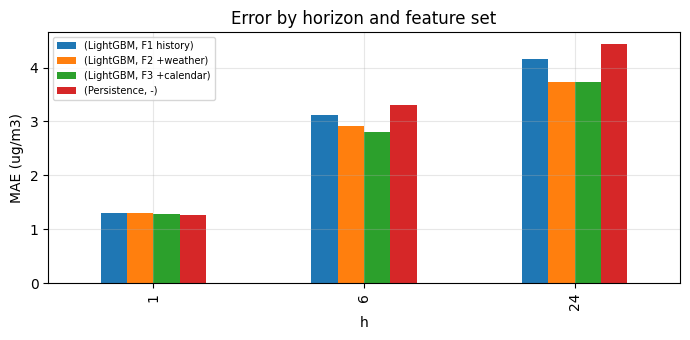

In [ ]:
try:
    import holidays as _hol
    HOLS = set(_hol.country_holidays("DE", subdiv="BB", years=range(2020, 2028)).keys())
except Exception:
    HOLS = set(); print("holidays package missing -> holidays ignored")

CAL_COLS = ["hour", "dow", "month", "is_weekend", "is_holiday", "heating_season"]

def calendar_feats(idx):
    loc = idx.tz_convert("Europe/Berlin")
    c = pd.DataFrame(index=idx)
    c["hour"] = loc.hour; c["dow"] = loc.dayofweek; c["month"] = loc.month
    c["is_weekend"] = (loc.dayofweek >= 5).astype(int)
    c["is_holiday"] = [int(d in HOLS) for d in loc.date]
    c["heating_season"] = loc.month.isin([10, 11, 12, 1, 2, 3, 4]).astype(int)
    return c

def air_group(c):
    if c.startswith("pm10_"): return "PM10 history"
    if c in WEATHER_FEATS: return "Weather"
    return "Calendar"

AIR_IDX = pd.date_range(CFG["AIR_START"], pd.Timestamp(CFG["AIR_END"]) + pd.Timedelta(hours=23), freq="h", tz="UTC")
pm10 = pm10_raw.reindex(AIR_IDX)
print("---- PM10 quality report ----")
print(f"hours: {len(pm10)}  missing: {pm10.isna().mean():.1%}  mean: {pm10.mean():.1f}  p95: {pm10.quantile(.95):.1f}  max: {pm10.max():.0f} ug/m3")
pm10 = pm10.interpolate(limit=3)                      # fill only short gaps (<=3 h)
print(f"missing after short-gap interpolation: {pm10.isna().mean():.1%}")

def build_air_features():
    F = pd.DataFrame(index=AIR_IDX); p = pm10
    F["pm10_lag_0"] = p                                # value known at prediction time t
    for l in [1, 2, 3, 6, 12, 24, 48]: F[f"pm10_lag_{l}"] = p.shift(l)
    for w in [6, 24, 72]: F[f"pm10_roll_mean_{w}"] = p.rolling(w, min_periods=max(2, w // 2)).mean()
    F["pm10_roll_std_24"] = p.rolling(24, min_periods=12).std()
    W = weather.reindex(AIR_IDX)
    for c in WEATHER_FEATS: F[c] = W[c]
    return F.join(calendar_feats(AIR_IDX))

F_AIR = build_air_features()
HIST = [c for c in F_AIR if c.startswith("pm10_")]
FEATSETS = {"F1 history": HIST, "F2 +weather": HIST + WEATHER_FEATS, "F3 +calendar": HIST + WEATHER_FEATS + CAL_COLS}

def time_split(n, fr=(.60, .15, .10, .15)):
    b = np.cumsum([int(n * f) for f in fr[:-1]])
    return np.arange(0, b[0]), np.arange(b[0], b[1]), np.arange(b[1], b[2]), np.arange(b[2], n)

def fit_lgb(kind, Xtr, ytr, Xva, yva, **over):
    p = dict(n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=40, subsample=0.8,
             subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
    p.update(over)
    M = lgb.LGBMRegressor if kind == "reg" else lgb.LGBMClassifier
    m = M(**p)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1" if kind == "reg" else "binary_logloss",
          callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
    return m

def contribs(model, X):
    """Exact TreeSHAP values (LightGBM pred_contrib). Regression: model units. Classification: log-odds."""
    c = model.predict(X, pred_contrib=True)
    return pd.DataFrame(np.asarray(c)[:, :-1], columns=X.columns, index=X.index)

def n_trees(m):
    return getattr(m, "best_iteration_", None) or getattr(m, "n_estimators_", None) or getattr(m, "n_iter_", None)

def horizon_data(h):
    y = pm10.shift(-h)
    ok = y.notna() & F_AIR["pm10_lag_0"].notna()
    X, yy = F_AIR[ok], y[ok]
    return X, yy, time_split(len(X))

def reg_metrics(y, p, p0):
    mae = mean_absolute_error(y, p); return mae, np.sqrt(mean_squared_error(y, p)), 1 - mae / mean_absolute_error(y, p0)

def ridge_fit(Xtr, ytr, Xva, yva):
    best = None
    for a in [0.1, 1, 10, 100, 1000]:
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=a)).fit(Xtr, ytr)
        e = mean_absolute_error(yva, m.predict(Xva))
        if best is None or e < best[0]: best = (e, a, m)
    return best[2], best[1]

rows, AIR_MODELS = [], {}
for h in CFG["HORIZONS"]:
    X, y, (tr, va, ca, te) = horizon_data(h)
    y_te, p0 = y.iloc[te], X.iloc[te]["pm10_lag_0"]
    mae, rmse, _ = reg_metrics(y_te, p0, p0)
    rows.append(dict(h=h, model="Persistence", feats="-", MAE=mae, RMSE=rmse, skill=0.0, note=""))
    for fs_name, cols in FEATSETS.items():
        if fs_name == "F3 +calendar":
            rm, alpha = ridge_fit(X.iloc[tr][cols], y.iloc[tr], X.iloc[va][cols], y.iloc[va])
            mae, rmse, sk = reg_metrics(y_te, rm.predict(X.iloc[te][cols]), p0)
            rows.append(dict(h=h, model="Ridge", feats=fs_name, MAE=mae, RMSE=rmse, skill=sk, note=f"alpha={alpha}"))
        m = fit_lgb("reg", X.iloc[tr][cols], y.iloc[tr], X.iloc[va][cols], y.iloc[va])
        mae, rmse, sk = reg_metrics(y_te, m.predict(X.iloc[te][cols]), p0)
        rows.append(dict(h=h, model="LightGBM", feats=fs_name, MAE=mae, RMSE=rmse, skill=sk, note=f"{n_trees(m)} trees"))
        if fs_name == "F3 +calendar": AIR_MODELS[h] = dict(model=m, ridge=rm, X=X, y=y, split=(tr, va, ca, te), cols=cols)
RES_AIR = pd.DataFrame(rows)
print("PM10 forecasting results on the held-out TEST period (chronological split, MAE in ug/m3)")
print("skill = 1 - MAE_model / MAE_persistence   (positive = better than persistence)")
display(RES_AIR.round(3)) if "display" in globals() else print(RES_AIR.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 3.5))
piv = RES_AIR[RES_AIR.feats.isin(["-", "F1 history", "F2 +weather", "F3 +calendar"]) & (RES_AIR.model != "Ridge")] \
    .pivot_table(index="h", columns=["model", "feats"], values="MAE")
piv.plot(kind="bar", ax=ax); ax.set_ylabel("MAE (ug/m3)"); ax.set_title("Error by horizon and feature set"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
RES_AIR.to_csv(OUT / "air_results.csv", index=False)

Main air model: LightGBM, horizon +6 h, 27 features


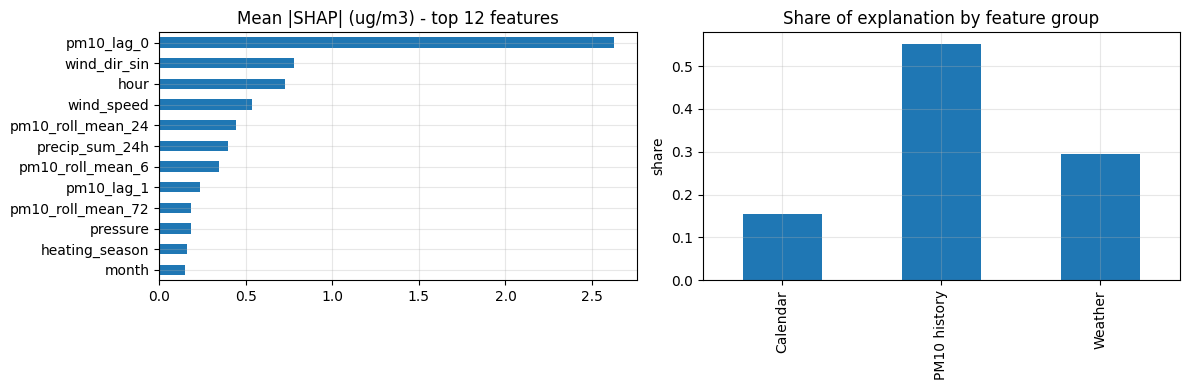

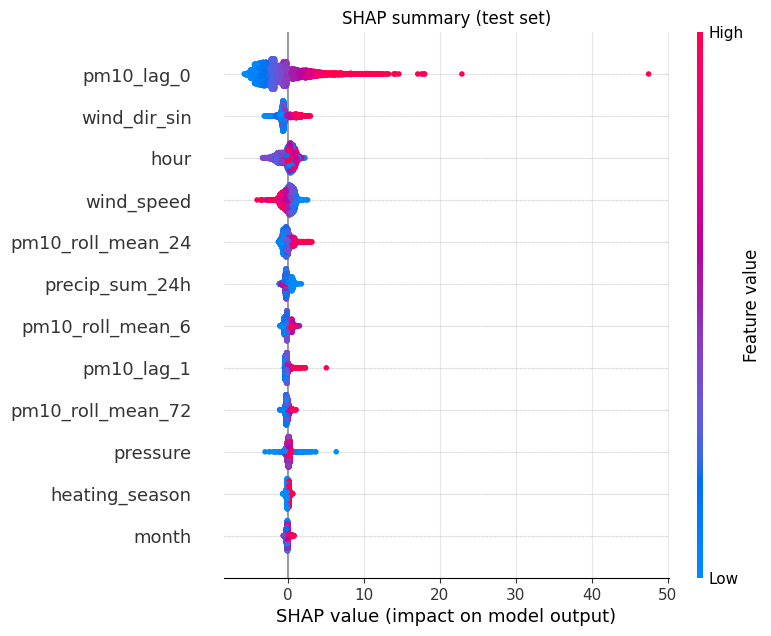


(1) Cross-method agreement: Spearman rank correlation of feature importances
              SHAP  Permutation  Ridge |coef|
SHAP          1.00         0.88          0.41
Permutation   0.88         1.00          0.41
Ridge |coef|  0.41         0.41          1.00

(2) Stability: Spearman between SHAP rankings of 3 consecutive test periods: [0.99 0.95 0.96]  (mean 0.97)

(3) Plausibility vs. simple atmospheric common sense:
   [PASS] higher wind_speed -> lower PM10
   [PASS] higher current PM10 -> higher forecast
   [PASS] heating season -> higher PM10 than non-heating

(4) Fidelity (deletion test): MAE increase when shuffling the top-5 SHAP features = +1.89  vs random 5 features = +0.13
    -> a faithful explanation names features whose removal hurts much more than random ones.

HYPER-PARAMETER STUDY (horizon +6 h)
Model *parameters* (tree splits, leaf values) are learned automatically. *Hyper-parameters* control complexity
(bias-variance). Here we vary complexity and measure accuracy AN

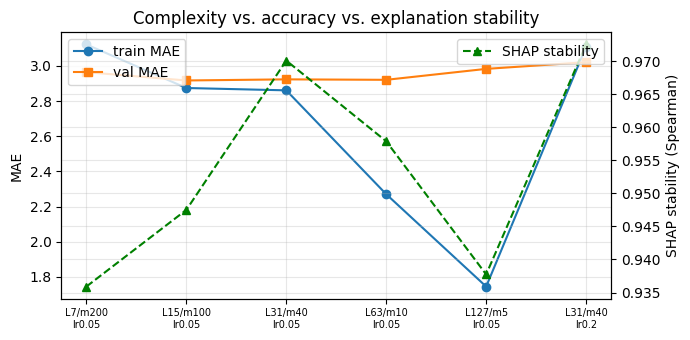

Reading it (typical pattern): the train/val gap grows with complexity (overfitting). 'trees' differs because early stopping picks the
number of boosting rounds from validation loss, so a higher learning_rate needs fewer trees. Very flexible models can
give less stable explanations. Pick the simplest setting near the validation optimum.

CONFORMAL INTERVALS: nominal 90%, interval = prediction +/- 11.2 ug/m3
Empirical coverage on test: 98.3%
Coverage by month: {5: 1.0, 6: 0.98, 7: 1.0, 8: 0.98, 9: 1.0, 10: 0.99, 11: 0.95, 12: 0.98}
Coverage when the wind sensor reads 50 % too low (drift): 97.9%  (compare with 98.3% above; a drop means the intervals lose reliability under drift)
Note: conformal guarantees assume exchangeable data; time series drift, so empirical coverage can fall below nominal. Report it.


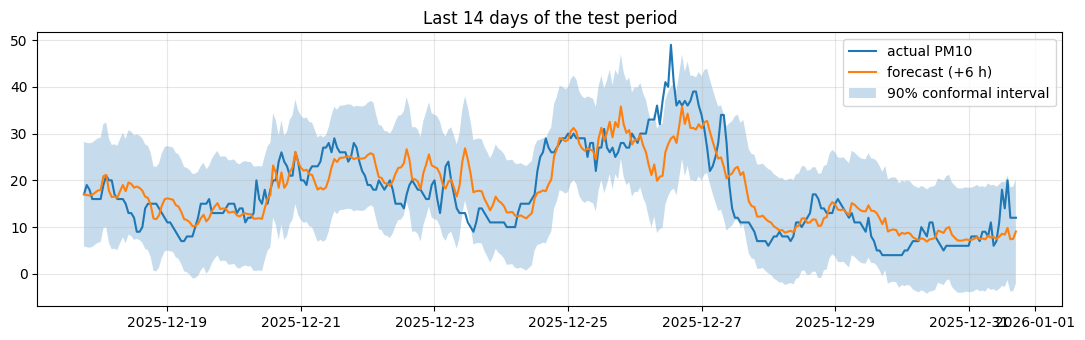

In [ ]:
H = CFG["MAIN_H"]; A = AIR_MODELS[H]
mA, cols_A = A["model"], A["cols"]
tr, va, ca, te = A["split"]
XA, yA = A["X"][cols_A], A["y"]
S_te = contribs(mA, XA.iloc[te])
imp = S_te.abs().mean().sort_values(ascending=False)

print(f"Main air model: LightGBM, horizon +{H} h, {len(cols_A)} features")
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
imp.head(12)[::-1].plot(kind="barh", ax=axs[0]); axs[0].set_title("Mean |SHAP| (ug/m3) - top 12 features")
grp = imp.groupby(imp.index.map(air_group)).sum(); (grp / grp.sum()).plot(kind="bar", ax=axs[1])
axs[1].set_title("Share of explanation by feature group"); axs[1].set_ylabel("share"); plt.tight_layout(); plt.show()
try:
    import shap
    shap.summary_plot(S_te.values, XA.iloc[te], show=False, max_display=12); plt.title("SHAP summary (test set)"); plt.show()
except Exception as e:
    print("shap beeswarm skipped:", repr(e)[:80])

def perm_importance(model, X, y, n_rep=2, n=2500, seed=SEED):
    r = np.random.default_rng(seed); sub = r.choice(len(X), min(n, len(X)), replace=False)
    Xs, ys = X.iloc[sub].copy(), y.iloc[sub]; base = mean_absolute_error(ys, model.predict(Xs)); out = {}
    for c in X.columns:
        d = []
        for _ in range(n_rep):
            keep = Xs[c].values.copy(); Xs[c] = r.permutation(keep)
            d.append(mean_absolute_error(ys, model.predict(Xs)) - base); Xs[c] = keep
        out[c] = np.mean(d)
    return pd.Series(out)

pimp = perm_importance(mA, XA.iloc[te], yA.iloc[te])
ridge_imp = pd.Series(np.abs(A["ridge"][-1].coef_), index=cols_A)
agree = pd.DataFrame({"SHAP": imp, "Permutation": pimp, "Ridge |coef|": ridge_imp})
print("\n(1) Cross-method agreement: Spearman rank correlation of feature importances")
print(agree.corr(method="spearman").round(2))

chunks = np.array_split(np.arange(len(te)), 3)
imps = [S_te.iloc[c].abs().mean() for c in chunks]
st = [spearmanr(imps[i], imps[j])[0] for i in range(3) for j in range(i + 1, 3)]
print(f"\n(2) Stability: Spearman between SHAP rankings of 3 consecutive test periods: {np.round(st, 2)}  (mean {np.mean(st):.2f})")

def corr_sign(feat):
    return spearmanr(XA.iloc[te][feat], S_te[feat])[0]
checks = {"higher wind_speed -> lower PM10": corr_sign("wind_speed") < 0,
          "higher current PM10 -> higher forecast": corr_sign("pm10_lag_0") > 0,
          "heating season -> higher PM10 than non-heating": S_te.loc[XA.iloc[te]["heating_season"] == 1, "heating_season"].mean()
                                                           > S_te.loc[XA.iloc[te]["heating_season"] == 0, "heating_season"].mean()}
print("\n(3) Plausibility vs. simple atmospheric common sense:")
for k, v in checks.items(): print(f"   [{'PASS' if v else 'CHECK'}] {k}")

k = 5; r = np.random.default_rng(1); Xd = XA.iloc[te]; base = mean_absolute_error(yA.iloc[te], mA.predict(Xd))
def shuffled_mae(cs):
    X2 = Xd.copy()
    for c in cs: X2[c] = r.permutation(X2[c].values)
    return mean_absolute_error(yA.iloc[te], mA.predict(X2)) - base
top_inc = shuffled_mae(list(imp.index[:k])); rnd_inc = np.mean([shuffled_mae(list(r.choice(cols_A, k, replace=False))) for _ in range(5)])
print(f"\n(4) Fidelity (deletion test): MAE increase when shuffling the top-{k} SHAP features = +{top_inc:.2f}  vs random {k} features = +{rnd_inc:.2f}")
print("    -> a faithful explanation names features whose removal hurts much more than random ones.")
agree.round(3).to_csv(OUT / "air_importance_agreement.csv")

# ---------- Why parameters change: hyper-parameter / stability study ----------
print("\n" + "=" * 70 + "\nHYPER-PARAMETER STUDY (horizon +%d h)" % H)
print("Model *parameters* (tree splits, leaf values) are learned automatically. *Hyper-parameters* control complexity")
print("(bias-variance). Here we vary complexity and measure accuracy AND explanation stability.")
grid = [(7, 200, .05), (15, 100, .05), (31, 40, .05), (63, 10, .05), (127, 5, .05), (31, 40, .2)]
rows = []
for nl, mcs, lr in grid:
    m = fit_lgb("reg", XA.iloc[tr], yA.iloc[tr], XA.iloc[va], yA.iloc[va], num_leaves=nl, min_child_samples=mcs, learning_rate=lr)
    Sv = contribs(m, XA.iloc[va]); half = len(Sv) // 2
    stab = spearmanr(Sv.iloc[:half].abs().mean(), Sv.iloc[half:].abs().mean())[0]
    rows.append(dict(num_leaves=nl, min_child_samples=mcs, learning_rate=lr, trees=n_trees(m),
                     train_MAE=mean_absolute_error(yA.iloc[tr], m.predict(XA.iloc[tr])),
                     val_MAE=mean_absolute_error(yA.iloc[va], m.predict(XA.iloc[va])),
                     test_MAE=mean_absolute_error(yA.iloc[te], m.predict(XA.iloc[te])), SHAP_stability=stab))
HP = pd.DataFrame(rows); print(HP.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.5)); ax2 = ax.twinx(); xs = range(len(HP))
ax.plot(xs, HP.train_MAE, "o-", label="train MAE"); ax.plot(xs, HP.val_MAE, "s-", label="val MAE")
ax2.plot(xs, HP.SHAP_stability, "^--", c="g", label="SHAP stability")
ax.set_xticks(list(xs)); ax.set_xticklabels([f"L{a}/m{b}\nlr{c}" for a, b, c, *_ in HP.itertuples(index=False)], fontsize=7)
ax.set_ylabel("MAE"); ax2.set_ylabel("SHAP stability (Spearman)"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.set_title("Complexity vs. accuracy vs. explanation stability"); plt.tight_layout(); plt.show()
print("Reading it (typical pattern): the train/val gap grows with complexity (overfitting). 'trees' differs because early stopping picks the")
print("number of boosting rounds from validation loss, so a higher learning_rate needs fewer trees. Very flexible models can")
print("give less stable explanations. Pick the simplest setting near the validation optimum.")
HP.to_csv(OUT / "air_hyperparameter_study.csv", index=False)

# ---------- Uncertainty: split-conformal prediction intervals ----------
def conformal_q(res, alpha):
    n = len(res); k = int(np.ceil((n + 1) * (1 - alpha))); return np.sort(res)[min(k, n) - 1]

res_cal = np.abs(yA.iloc[ca] - mA.predict(XA.iloc[ca]))
q_air = conformal_q(res_cal.values, CFG["ALPHA"])
pred_te = mA.predict(XA.iloc[te]); lo, hi = pred_te - q_air, pred_te + q_air
cover = ((yA.iloc[te].values >= lo) & (yA.iloc[te].values <= hi))
print("\n" + "=" * 70 + f"\nCONFORMAL INTERVALS: nominal {(1 - CFG['ALPHA']):.0%}, interval = prediction +/- {q_air:.1f} ug/m3")
print(f"Empirical coverage on test: {cover.mean():.1%}")
mon = pd.Series(cover, index=XA.iloc[te].index.tz_convert("Europe/Berlin").month).groupby(level=0).mean()
print("Coverage by month:", mon.round(2).to_dict())
Xw = XA.iloc[te].copy(); Xw["wind_speed"] = Xw["wind_speed"] * 0.5       # simulate a mis-calibrated wind sensor
pw = mA.predict(Xw); cw = ((yA.iloc[te].values >= pw - q_air) & (yA.iloc[te].values <= pw + q_air)).mean()
print(f"Coverage when the wind sensor reads 50 % too low (drift): {cw:.1%}  (compare with {cover.mean():.1%} above; a drop means the intervals lose reliability under drift)")
print("Note: conformal guarantees assume exchangeable data; time series drift, so empirical coverage can fall below nominal. Report it.")
last = slice(-24 * 14, None)
fig, ax = plt.subplots(figsize=(11, 3.5)); ix = XA.iloc[te].index[last]
ax.plot(ix, yA.iloc[te].values[last], label="actual PM10"); ax.plot(ix, pred_te[last], label=f"forecast (+{H} h)")
ax.fill_between(ix, lo[last], hi[last], alpha=.25, label="90% conformal interval"); ax.legend(); ax.set_title("Last 14 days of the test period")
plt.tight_layout(); plt.show()

Train events loaded: 59713  | cancelled: 4.0%  | missing delay: 0.0%
Timezone sanity check: 2.3% of events fall between 01:00 and 03:59 local time (should be small; if it is large, the archive timestamps are probably UTC, not Berlin time).
Events per day: 217  (very low numbers would mean the archive covers few Cottbus trains - check before trusting results)
Usable events: 57319 | late (>= 6 min): 10.4% | period 2024-06-30 .. 2025-03-31
Train types: {0: 'Bus', 1: 'DZ', 2: 'EC', 3: 'IC', 4: 'IRE', 5: 'L-RE', 6: 'RB', 7: 'RE'}

Train-delay results on the TEST period (late = delay >= 6 min). AUC 0.5 = random.
                   model   AUC  PR_AUC  Brier    F1  thr
Base rate per train type 0.572   0.084  0.068 0.152 0.15
     Logistic Regression 0.628   0.119  0.065 0.186 0.13
                LightGBM 0.690   0.151  0.062 0.218 0.15


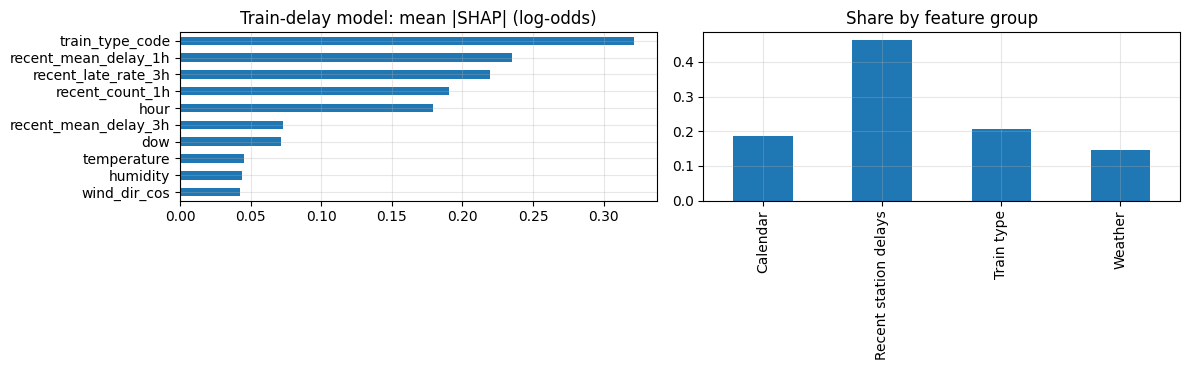

How much does WEATHER matter for delays?  Share of total |SHAP| = 14.6% (weather is often NOT the main driver of delays - a legitimate finding)

Conformal label sets (nominal 90%): coverage 92.2%, mean set size 0.99, share of 'certain' predictions (single label) 98.8%, 'unsure' (both labels) 0.0%


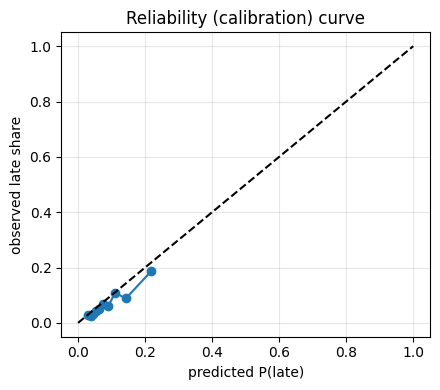

In [ ]:
ev = trains_raw.copy()
print(f"Train events loaded: {len(ev)}  | cancelled: {ev['is_canceled'].mean():.1%}  | missing delay: {ev['delay_in_min'].isna().mean():.1%}")
_hl = ev["time_utc"].dt.tz_convert("Europe/Berlin").dt.hour
print(f"Timezone sanity check: {((_hl >= 1) & (_hl <= 3)).mean():.1%} of events fall between 01:00 and 03:59 local time (should be small; "
      f"if it is large, the archive timestamps are probably UTC, not Berlin time).")
print(f"Events per day: {len(ev) / max(1, ev['time_utc'].dt.date.nunique()):.0f}  (very low numbers would mean the archive covers few Cottbus trains - check before trusting results)")
ev = ev[(~ev["is_canceled"]) & ev["delay_in_min"].notna()].copy()
ev["delay"] = ev["delay_in_min"].clip(lower=0)
ev["late"] = (ev["delay"] >= CFG["LATE_MIN"]).astype(int)
ev = ev.sort_values("time_utc").reset_index(drop=True)
ev["hour_utc"] = ev["time_utc"].dt.floor("h")
print(f"Usable events: {len(ev)} | late (>= {CFG['LATE_MIN']} min): {ev['late'].mean():.1%} | period {ev.time_utc.min():%Y-%m-%d} .. {ev.time_utc.max():%Y-%m-%d}")

def train_group(c):
    if c.startswith("recent_"): return "Recent station delays"
    if c == "train_type_code": return "Train type"
    if c in WEATHER_FEATS: return "Weather"
    return "Calendar"

def build_train_frame(ev):
    hrs = pd.date_range(ev.hour_utc.min(), ev.hour_utc.max(), freq="h")
    g = ev.groupby("hour_utc").agg(n=("late", "size"), dsum=("delay", "sum"), l=("late", "sum")).reindex(hrs).fillna(0)
    R = pd.DataFrame(index=hrs)               # all 'recent_*' use ONLY past hours (shift(1)) -> no leakage
    R["recent_count_1h"] = g.n.shift(1)
    R["recent_mean_delay_1h"] = (g.dsum / g.n.replace(0, np.nan)).shift(1)
    n3, d3, l3 = g.n.rolling(3).sum().shift(1), g.dsum.rolling(3).sum().shift(1), g.l.rolling(3).sum().shift(1)
    R["recent_mean_delay_3h"] = d3 / n3.replace(0, np.nan)
    R["recent_late_rate_3h"] = l3 / n3.replace(0, np.nan)
    Rj = R.reindex(ev.hour_utc).reset_index(drop=True)
    Wj = weather.reindex(ev.hour_utc)[WEATHER_FEATS].reset_index(drop=True)
    cats = sorted(ev.train_type.astype(str).unique())
    X = pd.DataFrame({"train_type_code": ev.train_type.astype(str).map({c: i for i, c in enumerate(cats)}).values})
    X = pd.concat([X, Rj, Wj], axis=1)
    cal = calendar_feats(pd.DatetimeIndex(ev.time_utc)).reset_index(drop=True)
    return pd.concat([X, cal], axis=1), cats

XT, TYPE_CATS = build_train_frame(ev); yT = ev["late"].reset_index(drop=True); timesT = pd.DatetimeIndex(ev.time_utc)
trT, vaT, caT, teT = time_split(len(XT))
print("Train types:", dict(enumerate(TYPE_CATS)))

base_rate = yT.iloc[trT].groupby(XT.iloc[trT]["train_type_code"]).mean()
p_base = XT.iloc[teT]["train_type_code"].map(base_rate).fillna(yT.iloc[trT].mean()).values
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.5, max_iter=500)).fit(XT.iloc[trT], yT.iloc[trT])
mT = fit_lgb("clf", XT.iloc[trT], yT.iloc[trT], XT.iloc[vaT], yT.iloc[vaT], num_leaves=15, min_child_samples=50)

def best_f1_thr(y, p):
    ts = np.linspace(.05, .8, 40); return ts[int(np.argmax([f1_score(y, p >= t) for t in ts]))]

def clf_row(name, p):
    t = best_f1_thr(yT.iloc[vaT], pv[name]) if name in pv else 0.5
    yt = yT.iloc[teT]
    return dict(model=name, AUC=roc_auc_score(yt, p), PR_AUC=average_precision_score(yt, p), Brier=brier_score_loss(yt, p),
                F1=f1_score(yt, p >= t), thr=round(float(t), 2))
pv = {"Base rate per train type": XT.iloc[vaT]["train_type_code"].map(base_rate).fillna(yT.iloc[trT].mean()).values,
      "Logistic Regression": lr.predict_proba(XT.iloc[vaT])[:, 1], "LightGBM": mT.predict_proba(XT.iloc[vaT])[:, 1]}
pt = {"Base rate per train type": p_base, "Logistic Regression": lr.predict_proba(XT.iloc[teT])[:, 1], "LightGBM": mT.predict_proba(XT.iloc[teT])[:, 1]}
RES_TR = pd.DataFrame([clf_row(k, v) for k, v in pt.items()])
print("\nTrain-delay results on the TEST period (late = delay >= %d min). AUC 0.5 = random." % CFG["LATE_MIN"])
print(RES_TR.round(3).to_string(index=False)); RES_TR.to_csv(OUT / "train_results.csv", index=False)

S_T = contribs(mT, XT.iloc[teT]); impT = S_T.abs().mean().sort_values(ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
impT.head(10)[::-1].plot(kind="barh", ax=axs[0]); axs[0].set_title("Train-delay model: mean |SHAP| (log-odds)")
gT = impT.groupby(impT.index.map(train_group)).sum(); (gT / gT.sum()).plot(kind="bar", ax=axs[1]); axs[1].set_title("Share by feature group")
plt.tight_layout(); plt.show()
print("How much does WEATHER matter for delays?  Share of total |SHAP| =", f"{gT.get('Weather', 0) / gT.sum():.1%}",
      "(weather is often NOT the main driver of delays - a legitimate finding)")

p_cal = mT.predict_proba(XT.iloc[caT])[:, 1]; y_cal = yT.iloc[caT].values
score_cal = np.where(y_cal == 1, 1 - p_cal, p_cal)                 # nonconformity: 1 - p(true class)
q_tr = conformal_q(score_cal, CFG["ALPHA"])
p_te = pt["LightGBM"]; y_te_T = yT.iloc[teT].values
in_late, in_ok = (1 - p_te) <= q_tr, p_te <= q_tr
covT = np.where(y_te_T == 1, in_late, in_ok).mean(); size = in_late.astype(int) + in_ok.astype(int)
print(f"\nConformal label sets (nominal {1 - CFG['ALPHA']:.0%}): coverage {covT:.1%}, mean set size {size.mean():.2f}, "
      f"share of 'certain' predictions (single label) {np.mean(size == 1):.1%}, 'unsure' (both labels) {np.mean(size == 2):.1%}")
dec = pd.qcut(p_te, 10, duplicates="drop"); rel = pd.DataFrame({"pred": p_te, "obs": y_te_T}).groupby(dec).mean()
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.plot(rel.pred, rel.obs, "o-"); ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("predicted P(late)")
ax.set_ylabel("observed late share"); ax.set_title("Reliability (calibration) curve"); plt.tight_layout(); plt.show()

Running drift experiment: AIR module (this takes a few minutes)...

AIR module - which detector reacts first? (delay in days after the fault starts; lower is better)
                                                detection_rate  mean_delay_days  false_alarm_rate  names_right_feature
fault                              detector                                                                           
PM10 sensor stuck (history frozen) error                  0.25            9.000             0.000                  NaN
                                   explanation            0.50            3.000             0.004                0.500
                                   input                  1.00            4.750             0.087                0.500
temperature sensor +6 C offset     error                  0.00              NaN             0.000                  NaN
                                   explanation            0.00              NaN             0.004                  NaN
 

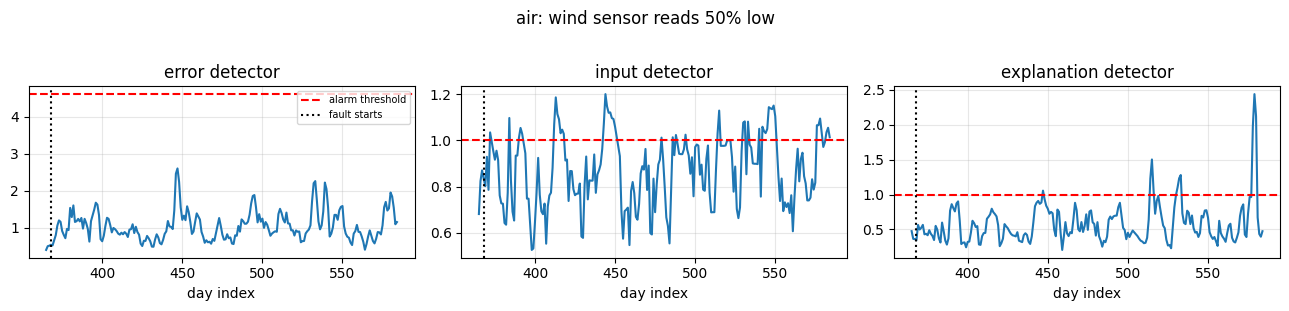

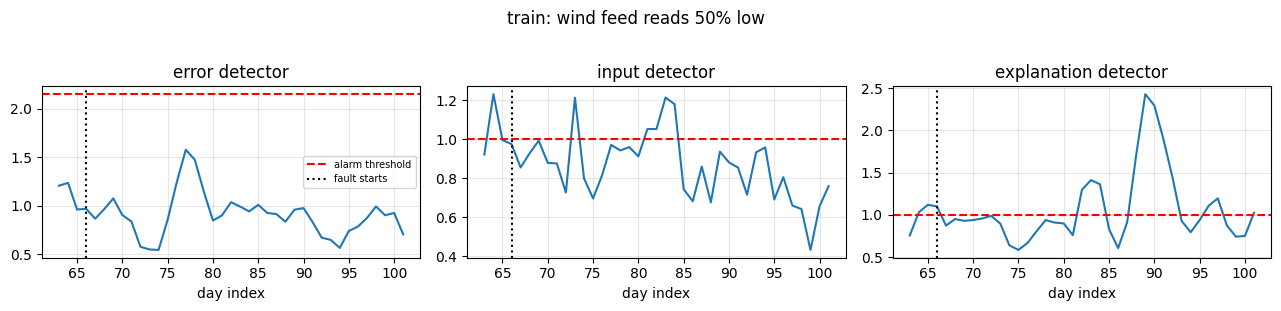

If 'explanation' is not faster than 'error' or 'input' for some faults, report that honestly: it IS a result.
Explanation drift also tells you WHICH feature changed ('names_right_feature'), which an error alarm cannot.


In [ ]:
def stream_stats(day, loss, X, S, cols, W, BASE, GAP, eval_days, max_ref=1500):
    """Raw per-day statistics: loss ratio + per-feature KS (inputs) + per-feature Wasserstein (SHAP values)."""
    Xv, Sv = X[cols].to_numpy(float), S[cols].to_numpy(float)
    scale = np.abs(Sv).mean(axis=0).sum() + 1e-9
    nf = len(cols); out = []
    for d in eval_days:
        w0, w1 = np.searchsorted(day, d - W + 1, "left"), np.searchsorted(day, d, "right")
        r0, r1 = np.searchsorted(day, d - W - GAP - BASE + 1, "left"), np.searchsorted(day, d - W - GAP, "right")
        if w1 - w0 < 5 or r1 - r0 < 50:
            out.append([d] + [np.nan] * (1 + 2 * nf)); continue
        ri = np.arange(r0, r1)
        if len(ri) > max_ref: ri = ri[np.linspace(0, len(ri) - 1, max_ref).astype(int)]
        err = loss[w0:w1].mean() / (loss[r0:r1].mean() + 1e-9)
        ks, wd = np.zeros(nf), np.zeros(nf)
        for j in range(nf):
            a, b = Xv[w0:w1, j], Xv[ri, j]; a, b = a[~np.isnan(a)], b[~np.isnan(b)]
            if len(a) > 3 and len(b) > 3: ks[j] = ks_2samp(a, b).statistic
            wd[j] = wasserstein_distance(Sv[w0:w1, j], Sv[ri, j]) / scale
        out.append([d, err] + list(ks) + list(wd))
    names = ["day", "err"] + [f"k::{c}" for c in cols] + [f"w::{c}" for c in cols]
    return pd.DataFrame(out, columns=names).set_index("day")

def derive(raw, cols, thr_k, thr_w):
    """Per-feature scores relative to that feature's own clean-data threshold; detector score = worst feature (alarm if > 1)."""
    K = np.nan_to_num(raw[[f"k::{c}" for c in cols]].to_numpy(float) / thr_k)
    Wd = np.nan_to_num(raw[[f"w::{c}" for c in cols]].to_numpy(float) / thr_w)
    return pd.DataFrame({"err": raw["err"], "inp": K.max(axis=1), "inp_top": [cols[i] for i in K.argmax(axis=1)],
                         "exp": Wd.max(axis=1), "exp_top": [cols[i] for i in Wd.argmax(axis=1)]}, index=raw.index)

FAULTS_AIR = {
    "wind sensor reads 50% low": (lambda c: ["wind_speed"], lambda s: s * 0.5),
    "temperature sensor +6 C offset": (lambda c: ["temperature"], lambda s: s + 6),
    "PM10 sensor stuck (history frozen)": (lambda c: [x for x in c if x.startswith("pm10_")], lambda s: pd.Series(s.iloc[0], index=s.index)),
}
FAULTS_TRAIN = {
    "wind feed reads 50% low": (lambda c: ["wind_speed"], lambda s: s * 0.5),
    "temperature feed +6 C offset": (lambda c: ["temperature"], lambda s: s + 6),
    "delay feed outage (recent_* = 0)": (lambda c: [x for x in c if x.startswith("recent_")], lambda s: s * 0),
}
DET = {"error": "err", "input": "inp", "explanation": "exp"}
EXAMPLES = {}

def drift_experiment(tag, model, kind, X, y, times, n_clean, faults, group_fn, W=3, BASE=28, GAP=7, n_trials=None, seed=0):
    n_trials = n_trials or CFG["N_TRIALS"]
    times = pd.DatetimeIndex(times); fl = times.floor("D"); day = np.asarray((fl - fl.min()).days)
    mon_cols = [c for c in X.columns if group_fn(c) != "Calendar"]
    def loss_of(Xm, ym):
        if kind == "reg": return np.abs(ym - model.predict(Xm))
        p = np.clip(model.predict_proba(Xm)[:, 1], 1e-4, 1 - 1e-4); return -(ym * np.log(p) + (1 - ym) * np.log(1 - p))
    y = np.asarray(y, float); loss0 = np.asarray(loss_of(X, y)); S0 = contribs(model, X)
    first_ok = day[0] + W + GAP + BASE; clean_days = np.unique(day[:n_clean]); clean_days = clean_days[clean_days >= first_ok]
    test_days = np.unique(day[n_clean:])
    if len(clean_days) < 10 or len(test_days) < 20:
        print(f"[{tag}] not enough days (clean eval {len(clean_days)}, test {len(test_days)}) - results will be weak.")
    raw_clean = stream_stats(day, loss0, X, S0, mon_cols, W, BASE, GAP, clean_days)
    q = CFG["THR_Q"]
    thr_k = np.maximum(np.nanquantile(raw_clean[[f"k::{c}" for c in mon_cols]].to_numpy(float), q, axis=0), 0.05)
    thr_w = np.maximum(np.nanquantile(raw_clean[[f"w::{c}" for c in mon_cols]].to_numpy(float), q, axis=0), 1e-3)
    thr = {"error": float(np.nanquantile(raw_clean["err"], q)), "input": 1.0, "explanation": 1.0}
    lo_d, hi_d = test_days[0] + 3, max(test_days[0] + 3, test_days[-1] - 10)
    t0s = np.unique(np.linspace(lo_d, hi_d, n_trials).round().astype(int)); rows = []
    for fname, (colfn, tf) in faults.items():
        inj = [c for c in colfn(list(X.columns)) if c in X.columns]
        for t0 in t0s:
            Xf = X.copy(); m = (day >= t0) & (np.arange(len(day)) >= n_clean)
            for c in inj: Xf.loc[m, c] = tf(Xf.loc[m, c])
            loss_f, S_f = loss0.copy(), S0.copy()
            tm = np.arange(len(day)) >= n_clean
            loss_f[tm] = loss_of(Xf[tm], y[tm]); S_f.loc[tm, :] = contribs(model, Xf[tm]).values
            st = derive(stream_stats(day, loss_f, Xf, S_f, mon_cols, W, BASE, GAP, test_days), mon_cols, thr_k, thr_w)
            if (tag, fname) not in EXAMPLES: EXAMPLES[(tag, fname)] = (st.copy(), dict(thr), int(t0), [c for c in inj])
            for dn, col in DET.items():
                hit = st[col] > thr[dn]; alarm = hit & hit.shift(1, fill_value=False)
                pre, post = alarm[alarm.index < t0], alarm[alarm.index >= t0]
                fa = pre.mean() if len(pre) else np.nan
                first = post.index[post.values.argmax()] if post.any() else None
                if first is not None and (first - t0) > CFG["MAX_DELAY_DAYS"]: first = None   # later alarms are unrelated to the fault
                top = None
                if first is not None and dn != "error":
                    top = st.loc[first, "inp_top" if dn == "input" else "exp_top"] in inj
                rows.append(dict(module=tag, fault=fname, t0=int(t0), detector=dn, detected=first is not None,
                                 delay_days=(first - t0) if first is not None else np.nan, false_alarm_rate=fa, names_right_feature=top))
    T = pd.DataFrame(rows)
    S = T.groupby(["fault", "detector"]).agg(detection_rate=("detected", "mean"), mean_delay_days=("delay_days", "mean"),
                                               false_alarm_rate=("false_alarm_rate", "mean"),
                                               names_right_feature=("names_right_feature", lambda s: s.dropna().astype(float).mean() if s.notna().any() else np.nan)).round(3)
    return S, T, thr

nA_clean = len(va) + len(ca)
idxA = np.concatenate([va, ca, te]); XAs = XA.iloc[idxA].reset_index(drop=True); yAs = yA.iloc[idxA].values
timesA = XA.iloc[idxA].index
print("Running drift experiment: AIR module (this takes a few minutes)...")
SUM_A, TRI_A, THR_A = drift_experiment("air", mA, "reg", XAs, yAs, timesA, nA_clean, FAULTS_AIR, air_group, W=3, BASE=28, GAP=7)
print("\nAIR module - which detector reacts first? (delay in days after the fault starts; lower is better)")
print(SUM_A.to_string())

nT_clean = len(vaT) + len(caT)
idxT = np.concatenate([vaT, caT, teT]); XTs = XT.iloc[idxT].reset_index(drop=True); yTs = yT.iloc[idxT].values
print("\nRunning drift experiment: TRAIN module (SAME code, no changes)...")
SUM_T, TRI_T, THR_T = drift_experiment("train", mT, "clf", XTs, yTs, timesT[idxT], nT_clean, FAULTS_TRAIN, train_group, W=3, BASE=14, GAP=3)
print("\nTRAIN module - which detector reacts first?")
print(SUM_T.to_string())
SUM_A.to_csv(OUT / "drift_summary_air.csv"); SUM_T.to_csv(OUT / "drift_summary_train.csv")

print("\nWindow-length sensitivity (air module, wind fault only): short windows react faster but raise more false alarms")
first_fault = {list(FAULTS_AIR)[0]: FAULTS_AIR[list(FAULTS_AIR)[0]]}
sens = []
for Wd in [1, 3, 7]:
    s, _, _ = drift_experiment(f"air-W{Wd}", mA, "reg", XAs, yAs, timesA, nA_clean, first_fault, air_group, W=Wd, BASE=28, GAP=7, n_trials=2)
    s = s.reset_index(); s["window_days"] = Wd; sens.append(s)
SENS = pd.concat(sens)[["window_days", "detector", "detection_rate", "mean_delay_days", "false_alarm_rate"]]
print(SENS.to_string(index=False)); SENS.to_csv(OUT / "drift_window_sensitivity.csv", index=False)

def plot_example(tag, fault, ax_list=None):
    st, thr, t0, inj = EXAMPLES[(tag, fault)]
    fig, axs = plt.subplots(1, 3, figsize=(13, 3))
    for ax, (dn, col) in zip(axs, DET.items()):
        ax.plot(st.index, st[col]); ax.axhline(thr[dn], c="r", ls="--", label="alarm threshold"); ax.axvline(t0, c="k", ls=":", label="fault starts")
        ax.set_title(f"{dn} detector"); ax.set_xlabel("day index")
    axs[0].legend(fontsize=7); fig.suptitle(f"{tag}: {fault}", y=1.02); plt.tight_layout(); plt.show()
plot_example("air", list(FAULTS_AIR)[0]); plot_example("train", list(FAULTS_TRAIN)[0])
print("If 'explanation' is not faster than 'error' or 'input' for some faults, report that honestly: it IS a result.")
print("Explanation drift also tells you WHICH feature changed ('names_right_feature'), which an error alarm cannot.")

In [ ]:
FRIENDLY = {"pm10_lag_0": "the current PM10 level", "pm10_lag_1": "PM10 one hour ago", "pm10_lag_24": "PM10 24 hours ago",
            "pm10_roll_mean_24": "the 24-hour average PM10", "pm10_roll_mean_6": "the 6-hour average PM10", "wind_speed": "wind speed",
            "temperature": "temperature", "humidity": "humidity", "precip": "rain", "pressure": "air pressure", "heating_season": "the heating season",
            "recent_mean_delay_1h": "the average delay in the last hour", "recent_late_rate_3h": "the share of late trains in the last 3 hours",
            "train_type_code": "the train type", "hour": "the hour of day", "dow": "the weekday", "month": "the month"}
def fname(c): return FRIENDLY.get(c, c.replace("_", " "))

def make_claims(s_row, k=3):
    top = s_row.abs().sort_values(ascending=False).head(k).index
    return [dict(feature=f, direction="raised" if s_row[f] > 0 else "lowered", value=abs(float(s_row[f]))) for f in top]

def claims_to_text(claims, target, unit):
    return "; ".join(f"{fname(c['feature'])} {c['direction']} the {target} by {c['value']:.2f} {unit}" for c in claims)

def explain_air(s_row, pred, lo, hi):
    return f"Forecast {pred:.1f} ug/m3 (90% range {lo:.1f}-{hi:.1f}). Main drivers: " + claims_to_text(make_claims(s_row), "forecast", "ug/m3") + "."

def explain_train(s_row, p, in_late, in_ok):
    verdict = "uncertain (both outcomes plausible)" if in_late and in_ok else ("likely LATE" if in_late else "likely ON TIME")
    return f"Train is {verdict}; P(late) = {p:.0%}. Main drivers: " + claims_to_text(make_claims(s_row), "late-risk", "log-odds") + "."

PAT = re.compile(r"^(?P<name>.+?) (?P<dir>raised|lowered) the [a-z\- ]+? by (?P<val>[0-9.]+)")
def parse_text(text, columns):
    n2f = {fname(c): c for c in columns}
    body = text.split("Main drivers:")[-1].strip().rstrip(".")
    out = []
    for part in body.split(";"):
        m = PAT.match(part.strip())
        out.append(dict(feature=n2f.get(m["name"].strip()) if m else None, direction=m["dir"] if m else None, value=float(m["val"]) if m else np.nan))
    return out

def verify(text, s_row, top_n=5, rel_tol=0.1):
    """Every claim must name a real top-N driver, with the right sign and (approximately) the right magnitude."""
    ok = []
    for c in parse_text(text, s_row.index):
        f = c["feature"]
        if f is None or f not in s_row.abs().sort_values(ascending=False).head(top_n).index: ok.append(False); continue
        v = s_row[f]; sign_ok = (v > 0) == (c["direction"] == "raised")
        ok.append(bool(sign_ok and abs(c["value"] - abs(v)) <= max(0.05, rel_tol * abs(v))))
    return len(ok) > 0 and all(ok)

sample = np.random.default_rng(0).choice(len(S_te), 300, replace=False)
faith, flipped, swapped, scaled = [], [], [], []
for i in sample:
    s = S_te.iloc[i]; t = explain_air(s, 0, 0, 0)
    faith.append(verify(t, s))
    flipped.append(verify(t.replace(" raised ", " TMP ").replace(" lowered ", " raised ").replace(" TMP ", " lowered "), s))
    weakest = fname(s.abs().sort_values().index[0]); first = fname(make_claims(s)[0]["feature"])
    swapped.append(verify(t.replace(first, weakest, 1), s))
    scaled.append(verify(re.sub(r"by ([0-9.]+)", lambda m: f"by {float(m[1]) * 2:.2f}", t, count=1), s))
print("Language-layer verifier (300 test rows):")
print(f"  faithful explanations accepted : {np.mean(faith):.1%}")
print(f"  wrong direction rejected       : {1 - np.mean(flipped):.1%}")
print(f"  wrong feature rejected         : {1 - np.mean(swapped):.1%}")
print(f"  wrong magnitude (x2) rejected  : {1 - np.mean(scaled):.1%}")
print("Any LLM can be plugged in: let it rewrite the structured claims, then run verify() on its output before showing it.")
i0 = int(sample[0]); print("\nExample air explanation:\n ", explain_air(S_te.iloc[i0], mA.predict(XA.iloc[te].iloc[[i0]])[0], pred_te[i0] - q_air, pred_te[i0] + q_air))
j0 = 0; print("Example train explanation:\n ", explain_train(S_T.iloc[j0], p_te[j0], in_late[j0], in_ok[j0]))

Language-layer verifier (300 test rows):
  faithful explanations accepted : 100.0%
  wrong direction rejected       : 100.0%
  wrong feature rejected         : 100.0%
  wrong magnitude (x2) rejected  : 100.0%
Any LLM can be plugged in: let it rewrite the structured claims, then run verify() on its output before showing it.

Example air explanation:
  Forecast 12.9 ug/m3 (90% range 1.8-24.1). Main drivers: the current PM10 level lowered the forecast by 3.04 ug/m3; wind speed raised the forecast by 1.14 ug/m3; the 24-hour average PM10 raised the forecast by 0.95 ug/m3.
Example train explanation:
  Train is likely ON TIME; P(late) = 4%. Main drivers: the share of late trains in the last 3 hours lowered the late-risk by 0.32 log-odds; the train type lowered the late-risk by 0.27 log-odds; the average delay in the last hour lowered the late-risk by 0.25 log-odds.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def banner():
    return f"<b>Data sources (historical, not live):</b> weather = {W_SRC}; PM10 = {PM_SRC}; trains = {TR_SRC}"

out_w, out_a, out_t, out_m = (widgets.Output() for _ in range(4))

# --- Weather tab (stand-alone) ---
days_w = widgets.IntSlider(value=30, min=7, max=365, description="last days")
def draw_weather(*_):
    with out_w:
        clear_output(wait=True)
        w = weather.dropna(subset=["temperature"]).iloc[-24 * days_w.value:]
        fig, axs = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
        for ax, c, t in zip(axs.ravel(), ["temperature", "precip", "wind_speed", "humidity"], ["Temperature (C)", "Precipitation (mm/h)", "Wind speed (km/h)", "Humidity (%)"]):
            ax.plot(w.index, w[c], lw=.7); ax.set_title(t)
        plt.tight_layout(); plt.show()
days_w.observe(draw_weather, "value")

# --- Air tab ---
te_idx = XA.iloc[te].index
sl_a = widgets.IntSlider(value=len(te_idx) - 1, min=0, max=len(te_idx) - 1, description="test hour #", layout=widgets.Layout(width="70%"))
def draw_air(*_):
    with out_a:
        clear_output(wait=True)
        i = sl_a.value; s = S_te.iloc[i]
        txt = explain_air(s, pred_te[i], pred_te[i] - q_air, pred_te[i] + q_air)
        print(f"Time (UTC): {te_idx[i]:%Y-%m-%d %H:%M}   actual PM10 at +{H} h: {yA.iloc[te].iloc[i]:.1f}")
        print(txt); print("Verified against SHAP values:", verify(txt, s))
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
        s.reindex(s.abs().sort_values(ascending=False).head(8).index)[::-1].plot(kind="barh", ax=axs[0]); axs[0].set_title("Why? SHAP contributions (ug/m3)")
        a = max(0, i - 24 * 7); ix = te_idx[a:i + 1]
        axs[1].plot(ix, yA.iloc[te].values[a:i + 1], label="actual"); axs[1].plot(ix, pred_te[a:i + 1], label="forecast")
        axs[1].fill_between(ix, lo[a:i + 1], hi[a:i + 1], alpha=.25, label="90% range"); axs[1].legend(); axs[1].set_title("Previous 7 days")
        plt.tight_layout(); plt.show()
sl_a.observe(draw_air, "value")

# --- Trains tab ---
sl_t = widgets.IntSlider(value=0, min=0, max=len(teT) - 1, description="train #", layout=widgets.Layout(width="70%"))
def draw_train(*_):
    with out_t:
        clear_output(wait=True)
        j = sl_t.value; s = S_T.iloc[j]; row = ev.iloc[teT[j]]
        txt = explain_train(s, p_te[j], in_late[j], in_ok[j])
        print(f"{row.time_utc:%Y-%m-%d %H:%M} UTC | type {row.train_type} | actual delay {row.delay:.0f} min ({'LATE' if row.late else 'on time'})")
        print(txt); print("Verified against SHAP values:", verify(txt, s))
        fig, ax = plt.subplots(figsize=(6, 3)); s.reindex(s.abs().sort_values(ascending=False).head(8).index)[::-1].plot(kind="barh", ax=ax)
        ax.set_title("Why? SHAP contributions (log-odds)"); plt.tight_layout(); plt.show()
sl_t.observe(draw_train, "value")

# --- Trust monitor tab ---
opts = [("air", f) for f in FAULTS_AIR] + [("train", f) for f in FAULTS_TRAIN]
dd = widgets.Dropdown(options=[(f"{m}: {f}", (m, f)) for m, f in opts], description="inject fault")
def draw_mon(*_):
    with out_m:
        clear_output(wait=True)
        m, f = dd.value; plot_example(m, f)
        S = (SUM_A if m == "air" else SUM_T).loc[f]; print(S.to_string())
        print("\nTrust status of the clean test period (no fault): all detectors below threshold = AI reasoning stable.")
dd.observe(draw_mon, "value")

tabs = widgets.Tab(children=[widgets.VBox([days_w, out_w]), widgets.VBox([sl_a, out_a]), widgets.VBox([sl_t, out_t]), widgets.VBox([dd, out_m])])
for i, t in enumerate(["Weather", "Air quality AI", "Train delay AI", "Trust monitor"]): tabs.set_title(i, t)
display(widgets.HTML("<h2>SmartCity AI - Cottbus</h2>" + banner()))
display(tabs)
draw_weather(); draw_air(); draw_train(); draw_mon()

HTML(value='<h2>SmartCity AI - Cottbus</h2><b>Data sources (historical, not live):</b> weather = Open-Meteo hi…

In [ ]:
RES_AIR.to_csv(OUT / "air_results.csv", index=False)
print("Saved to", OUT.resolve(), ":", sorted(p.name for p in OUT.iterdir()))
try:
    from google.colab import files; import shutil
    shutil.make_archive("smartcity_outputs", "zip", OUT); files.download("smartcity_outputs.zip")
except Exception:
    pass

Saved to /content/smartcity_outputs : ['air_hyperparameter_study.csv', 'air_importance_agreement.csv', 'air_results.csv', 'drift_summary_air.csv', 'drift_summary_train.csv', 'drift_window_sensitivity.csv', 'train_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>